# Projeto Integrado - Ciência de Dados (ENG 4040)
## Grupo D — DataCast

**Tema:** Previsão de risco de enchentes na região Sudeste do Brasil

**Cliente:** Ministério do Meio Ambiente e Mudança do Clima


### Integrantes

| Nome do Integrante | Matrícula |
|---|---|
| Rodrigo Touma Costa | 2510583 |
| Raphael Vincenzo Maniero | 2510285 |
| Eduardo Luiz Meireles | 2510502 |
| Pedro Monteiro Bernardes | 2510962 |
| Daniel Santana | 2310995 |


---
### Sobre este notebook

Este notebook documenta o pipeline de dados do projeto DataCast, em três etapas:

1. **Integração das Bases de Dados** — união de INMET, CEMADEN e ANA/HidroWeb
2. **Limpeza e Tratamento de Dados** — valores ausentes, duplicatas e outliers
3. **Análise Exploratória de Dados (EDA)** — distribuições, correlações e padrões

Os arquivos de dados são muito grandes, então este notebook acessa os dados via Google Drive.


## 0. Configuração inicial

Monta o Google Drive (onde estão os arquivos de dados, que são grandes demais para upload direto no Colab) e importa as bibliotecas usadas no projeto.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import re
import unicodedata
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import random
PASTA_PROJETO = '/content/drive/MyDrive/Projeto Integrado - Ciência de Dados/Projeto - Ciência de Dados/'

## 1. Integração das Bases de Dados

In [ ]:
BASE = Path(PASTA_PROJETO)
INMET_DIR = BASE / "INMET_consolidado"
CEMADEN_DIR = BASE / "CEMADEN_consolidado"
ANA_ARQUIVO = BASE / "base_ana_estacao_dia.csv"

ESTADOS = ["RJ", "SP", "ES", "MG"]
ANOS = range(2019, 2025)

def normalizar_municipio(nome: str) -> str:
    if pd.isna(nome):
        return nome
    nome = str(nome).strip().upper()
    nome = unicodedata.normalize("NFKD", nome)
    nome = nome.encode("ascii", "ignore").decode("ascii")
    nome = re.sub(r"\s+", " ", nome)
    return nome

# 1. INMET

partes_inmet = []
for estado in ESTADOS:
    for ano in ANOS:
        caminho = INMET_DIR / f"{estado}_{ano}.csv"
        if caminho.exists():
            partes_inmet.append(pd.read_csv(caminho, encoding="utf-8"))
inmet = pd.concat(partes_inmet, ignore_index=True)

inmet["municipio_norm"] = inmet["Municipio"].map(normalizar_municipio)
inmet["data_hora"] = pd.to_datetime(
    inmet["Data"] + " " + inmet["Hora UTC"].str.replace(" UTC", "", regex=False),
    format="%Y/%m/%d %H%M",
    errors="coerce",
)
inmet["data"] = inmet["data_hora"].dt.date
inmet["hora"] = inmet["data_hora"].dt.hour

print(f"INMET: {len(inmet)} linhas horarias")

# 2. CEMADEN

partes_cemaden_hora = []
for estado in ESTADOS:
    for ano in ANOS:
        caminho = CEMADEN_DIR / f"{estado}_{ano}.csv"
        if not caminho.exists():
            continue
        x = pd.read_csv(caminho, encoding="utf-8")
        x["municipio_norm"] = x["municipio"].map(normalizar_municipio)
        x["data_hora"] = pd.to_datetime(x["datahora"], errors="coerce")
        x["data"] = x["data_hora"].dt.date
        x["hora"] = x["data_hora"].dt.hour

        agregado = (
            x.groupby(["municipio_norm", "data", "hora"], as_index=False)
            .agg(chuva_cemaden_mm=("valorMedida", "sum"))
        )
        partes_cemaden_hora.append(agregado)
        del x

cemaden_hora = pd.concat(partes_cemaden_hora, ignore_index=True)

cemaden_hora = (
    cemaden_hora.groupby(["municipio_norm", "data", "hora"], as_index=False)
    .agg(chuva_cemaden_mm=("chuva_cemaden_mm", "sum"))
)

print(f"CEMADEN agregado por hora: {len(cemaden_hora)} linhas")

# 3. ANA

ana = pd.read_csv(ANA_ARQUIVO, encoding="utf-8")
ana["municipio_norm"] = ana["municipio"].map(normalizar_municipio)
ana["data"] = pd.to_datetime(ana["data"], errors="coerce").dt.date

ana_diario = ana[["municipio_norm", "data", "cota_cm", "vazao_m3s"]].drop_duplicates(
    subset=["municipio_norm", "data"]
)

print(f"ANA (diario): {len(ana_diario)} linhas")

print("Municipios no INMET:", inmet['municipio_norm'].nunique())
print("Municipios no CEMADEN:", cemaden_hora['municipio_norm'].nunique())
print("Municipios na ANA:", ana_diario['municipio_norm'].nunique())

municipios_inmet = set(inmet['municipio_norm'].unique())
municipios_cemaden = set(cemaden_hora['municipio_norm'].unique())
municipios_ana = set(ana_diario['municipio_norm'].unique())

print("INMET e CEMADEN:", len(municipios_inmet & municipios_cemaden), "de", len(municipios_inmet))
print("INMET e ANA:", len(municipios_inmet & municipios_ana), "de", len(municipios_inmet))
print("Municipios do INMET SEM match no CEMADEN:", sorted(municipios_inmet - municipios_cemaden)[:10])
print("Municipios do INMET SEM match na ANA:", sorted(municipios_inmet - municipios_ana)[:10])

# 4. MERGE

base_horaria = inmet[
    ["municipio_norm", "UF", "data", "hora"]
    + [c for c in inmet.columns if c not in
       ("municipio_norm", "UF", "Municipio", "Estacao", "Data", "Hora UTC",
        "data_hora", "data", "hora")]
].copy()

integrado = base_horaria.merge(
    cemaden_hora, on=["municipio_norm", "data", "hora"], how="left"
)
integrado = integrado.merge(
    ana_diario, on=["municipio_norm", "data"], how="left"
)

print(f"\nDataset integrado final: {integrado.shape[0]} linhas x {integrado.shape[1]} colunas")
print(f"Municipios distintos: {integrado['municipio_norm'].nunique()}")
print(f"Periodo: {integrado['data'].min()} ate {integrado['data'].max()}")

SAIDA = BASE / "dataset_integrado.csv"
integrado.to_csv(SAIDA, index=False, encoding="utf-8")
print(f"\nSalvo em: {SAIDA}")

INMET: 15688560 linhas horarias


## 2. Limpeza e Tratamento de Dados

In [ ]:
df = pd.read_csv(PASTA_PROJETO + "dataset_integrado.csv")
print(f"Formato original: {df.shape[0]:,} linhas x {df.shape[1]} colunas")

df["RADIACAO GLOBAL (KJ/m²)"] = df["RADIACAO GLOBAL (KJ/m²)"].combine_first(df["RADIACAO GLOBAL (Kj/m²)"])
df = df.drop(columns=["RADIACAO GLOBAL (Kj/m²)"])

colunas_chave = ["municipio_norm", "UF", "data", "hora"]
colunas_numericas = [c for c in df.columns if c not in colunas_chave]

antes = len(df)
df = df.groupby(colunas_chave, as_index=False)[colunas_numericas].mean()
print(f"\nApós agregar estações por municipio+hora: {antes:,} -> {len(df):,} linhas")

dup_restante = df.duplicated(subset=colunas_chave).sum()
print(f"Duplicatas restantes (deveria ser 0): {dup_restante}")

municipios_com_cemaden = set(
    df.loc[df["chuva_cemaden_mm"].notna(), "municipio_norm"].unique()
)
municipios_com_ana = set(
    df.loc[df["cota_cm"].notna(), "municipio_norm"].unique()
)

df["tem_estacao_cemaden"] = df["municipio_norm"].isin(municipios_com_cemaden)
df["tem_estacao_ana"] = df["municipio_norm"].isin(municipios_com_ana)

print(f"\nMunicipios com CEMADEN: {len(municipios_com_cemaden)} de {df['municipio_norm'].nunique()}")
print(f"Municipios com ANA: {len(municipios_com_ana)} de {df['municipio_norm'].nunique()}")

COLUNAS_INTERPOLAVEIS = [
    'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)',
    'PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB)',
    'PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB)',
    'RADIACAO GLOBAL (KJ/m²)',
    'TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)',
    'TEMPERATURA DO PONTO DE ORVALHO (°C)',
    'TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C)',
    'TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C)',
    'TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C)',
    'TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT) (°C)',
    'UMIDADE REL. MAX. NA HORA ANT. (AUT) (%)',
    'UMIDADE REL. MIN. NA HORA ANT. (AUT) (%)',
    'UMIDADE RELATIVA DO AR, HORARIA (%)',
    'VENTO, DIREÇÃO HORARIA (gr) (° (gr))',
    'VENTO, RAJADA MAXIMA (m/s)',
    'VENTO, VELOCIDADE HORARIA (m/s)',
    'cota_cm',
    'vazao_m3s',
]
COLUNAS_CHUVA = ['PRECIPITAÇÃO TOTAL, HORÁRIO (mm)', 'chuva_cemaden_mm']

df = df.sort_values(['municipio_norm', 'data', 'hora']).reset_index(drop=True)

antes_interp = df[COLUNAS_INTERPOLAVEIS].isna().sum().sum()
df[COLUNAS_INTERPOLAVEIS] = (
    df.groupby('municipio_norm')[COLUNAS_INTERPOLAVEIS]
    .transform(lambda s: s.interpolate(method='linear', limit=6, limit_direction='both'))
)
depois_interp = df[COLUNAS_INTERPOLAVEIS].isna().sum().sum()
print(f"\nValores ausentes interpolados: {antes_interp:,} -> {depois_interp:,}")

print("\nChuva (NAO interpolada, mantida como ausente):")
print(df[COLUNAS_CHUVA].isna().sum())

df.to_csv("dataset_limpo_etapa1.csv", index=False, encoding="utf-8")
print(f"\nSalvo: dataset_limpo_etapa1.csv ({df.shape[0]:,} linhas x {df.shape[1]} colunas)")

colunas_numericas_analise = [
    'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)',
    'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)',
    'PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB)',
    'PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB)',
    'RADIACAO GLOBAL (KJ/m²)',
    'TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)',
    'TEMPERATURA DO PONTO DE ORVALHO (°C)',
    'TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C)',
    'TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C)',
    'TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C)',
    'TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT) (°C)',
    'UMIDADE REL. MAX. NA HORA ANT. (AUT) (%)',
    'UMIDADE REL. MIN. NA HORA ANT. (AUT) (%)',
    'UMIDADE RELATIVA DO AR, HORARIA (%)',
    'VENTO, DIREÇÃO HORARIA (gr) (° (gr))',
    'VENTO, RAJADA MAXIMA (m/s)',
    'VENTO, VELOCIDADE HORARIA (m/s)',
    'chuva_cemaden_mm',
    'cota_cm',
    'vazao_m3s',
]

outliers_por_variavel = {}
resumo_outliers = []

for col in colunas_numericas_analise:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    outliers = df[
        (df[col] < Q1 - 1.5 * IQR) |
        (df[col] > Q3 + 1.5 * IQR)
    ]

    outliers_por_variavel[col] = outliers
    resumo_outliers.append({'variavel': col, 'qtd_outliers': len(outliers)})
    print(f"{col}: {len(outliers):,} outliers (IQR)")

pd.DataFrame(resumo_outliers).to_csv("outliers_por_variavel.csv", index=False, encoding="utf-8")
print("\nSalvo: outliers_por_variavel.csv")

print("\nExemplos de outliers em chuva_cemaden_mm:")
print(outliers_por_variavel['chuva_cemaden_mm'][
    ['municipio_norm', 'data', 'hora', 'chuva_cemaden_mm']
].head(10))

LIMITES_FISICOS = {
    'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)': (860, 1050),
    'PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB)': (860, 1050),
    'PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB)': (860, 1050),
    'RADIACAO GLOBAL (KJ/m²)': (0, 4000),
    'chuva_cemaden_mm': (0, 400),
    'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)': (0, 400),
}

for col, (limite_inf, limite_sup) in LIMITES_FISICOS.items():
    invalidos = ((df[col] < limite_inf) | (df[col] > limite_sup)).sum()
    df.loc[(df[col] < limite_inf) | (df[col] > limite_sup), col] = pd.NA
    print(f"{col}: {invalidos:,} valores fora do limite fisico -> marcados como ausentes")

df.to_csv("dataset_limpo_final.csv", index=False, encoding="utf-8")
print(f"\nSalvo: dataset_limpo_final.csv ({df.shape[0]:,} linhas x {df.shape[1]} colunas)")

media = df[colunas_numericas_analise].mean()
mediana = df[colunas_numericas_analise].median()
minimo = df[colunas_numericas_analise].min()
maximo = df[colunas_numericas_analise].max()
desvio_padrao = df[colunas_numericas_analise].std()
nulos = df[colunas_numericas_analise].isna().sum()

estatisticas = pd.DataFrame({
    'min': minimo,
    'max': maximo,
    'mean': media,
    'median': mediana,
    'std': desvio_padrao,
    'nulos': nulos,
})
estatisticas['nulos_%'] = (estatisticas['nulos'] / len(df) * 100).round(1)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
print("\nEstatisticas descritivas:")
print(estatisticas.round(2))

estatisticas.round(2).to_csv("estatisticas_descritivas.csv", encoding="utf-8")
print("\nSalvo: estatisticas_descritivas.csv")

Formato original: 15,688,560 linhas x 25 colunas

Após agregar estações por municipio+hora: 15,688,560 -> 7,458,432 linhas
Duplicatas restantes (deveria ser 0): 0

Municipios com CEMADEN: 86 de 146
Municipios com ANA: 52 de 146

Valores ausentes interpolados: 28,278,171 -> 21,309,111

Chuva (NAO interpolada, mantida como ausente):
PRECIPITAÇÃO TOTAL, HORÁRIO (mm)    1133977
chuva_cemaden_mm                    3477314
dtype: int64

Salvo: dataset_limpo_etapa1.csv (7,458,432 linhas x 26 colunas)
PRECIPITAÇÃO TOTAL, HORÁRIO (mm): 469,530 outliers (IQR)
PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB): 72,306 outliers (IQR)
PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB): 71,862 outliers (IQR)
PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB): 72,023 outliers (IQR)
RADIACAO GLOBAL (KJ/m²): 120,810 outliers (IQR)
TEMPERATURA DO AR - BULBO SECO, HORARIA (°C): 78,468 outliers (IQR)
TEMPERATURA DO PONTO DE ORVALHO (°C): 68,133 outliers (IQR)
TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C): 56,5

## 3. Análise Exploratória de Dados (EDA)


### 3.2 Distribuição das Variáveis Numéricas

Estilo visual, rótulos curtos e nomes de colunas usados nas figuras das Seções 3.2 e 3.4 do relatório.

In [ ]:
AZUL, VERMELHO, VERDE, LARANJA, ROXO, CINZA = "#1f4e79", "#c0392b", "#27ae60", "#e67e22", "#8e44ad", "#7f8c8d"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.labelsize": 10, "axes.edgecolor": "#444444", "axes.linewidth": 0.8,
    "grid.color": "#dddddd", "grid.linewidth": 0.6,
    "legend.frameon": True, "legend.framealpha": 0.9,
    "figure.facecolor": "white", "axes.facecolor": "white",
})

CURTO = {
    "PRECIPITAÇÃO TOTAL, HORÁRIO (mm)": "Precipitação INMET (mm/h)",
    "PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)": "Pressão atmosf. (mB)",
    "PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB)": "Pressão máx. h-1 (mB)",
    "PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB)": "Pressão mín. h-1 (mB)",
    "RADIACAO GLOBAL (KJ/m²)": "Radiação global (KJ/m²)",
    "TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)": "Temperatura do ar (°C)",
    "TEMPERATURA DO PONTO DE ORVALHO (°C)": "Ponto de orvalho (°C)",
    "TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C)": "Temp. máx. h-1 (°C)",
    "TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C)": "Temp. mín. h-1 (°C)",
    "TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C)": "Orvalho máx. h-1 (°C)",
    "TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT) (°C)": "Orvalho mín. h-1 (°C)",
    "UMIDADE REL. MAX. NA HORA ANT. (AUT) (%)": "Umidade máx. h-1 (%)",
    "UMIDADE REL. MIN. NA HORA ANT. (AUT) (%)": "Umidade mín. h-1 (%)",
    "UMIDADE RELATIVA DO AR, HORARIA (%)": "Umidade relativa (%)",
    "VENTO, DIREÇÃO HORARIA (gr) (° (gr))": "Direção do vento (°)",
    "VENTO, RAJADA MAXIMA (m/s)": "Rajada máxima (m/s)",
    "VENTO, VELOCIDADE HORARIA (m/s)": "Velocidade do vento (m/s)",
    "chuva_cemaden_mm": "Chuva CEMADEN (mm/h)",
    "cota_cm": "Cota do rio (cm)",
    "vazao_m3s": "Vazão (m³/s)",
}

def curto(c):
    return CURTO.get(c, c)

P = "PRECIPITAÇÃO TOTAL, HORÁRIO (mm)"
C = "chuva_cemaden_mm"
V = "vazao_m3s"
CO = "cota_cm"
T = "TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)"
U = "UMIDADE RELATIVA DO AR, HORARIA (%)"
R = "RADIACAO GLOBAL (KJ/m²)"
PR = "PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)"

num = [c for c in df.select_dtypes(include=[np.number]).columns if c != "hora"]
print(f"{len(num)} variáveis numéricas consideradas nas Seções 3.2 e 3.4")

**Figura 1** — Distribuição das 20 variáveis numéricas. Variáveis com assimetria superior a 3 em módulo
(precipitação, chuva CEMADEN e vazão) recebem escala logarítmica no eixo vertical.

In [ ]:
fig, axes = plt.subplots(5, 4, figsize=(17, 18))
for ax, c in zip(axes.ravel(), num):
    v = df[c].dropna()
    ax.hist(v, bins=50, color=AZUL, edgecolor="white", linewidth=0.3)
    ax.set_title(curto(c), fontsize=10)
    ax.set_ylabel("Frequência", fontsize=8)
    ax.tick_params(labelsize=8)
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 4))
    if abs(v.skew()) > 3:
        ax.set_yscale("log")
        ax.set_ylabel("Frequência (log)", fontsize=8)

fig.suptitle(f"Seção 3.2 — Distribuição das variáveis numéricas ({len(df):,} registros horários, 2019–2024)",
             fontsize=14, fontweight="bold", y=0.997)
fig.tight_layout(rect=[0, 0, 1, 0.985])
fig.savefig("3_2_painel_histogramas.png")
plt.show()

**Figura 2 e Tabela 2** — Precipitação em duas leituras: todas as horas (a massa em zero) e apenas as horas
com registro positivo, onde a distribuição assume forma aproximadamente exponencial.

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for i, (col, cor, nome) in enumerate([(P, AZUL, "INMET"), (C, VERDE, "CEMADEN")]):
    v = df[col].dropna()
    ax = axes[i, 0]
    ax.hist(v, bins=60, color=cor, edgecolor="white", linewidth=0.3)
    ax.set_yscale("log")
    ax.set_title(f"{nome} — todas as horas  ({(v == 0).mean() * 100:.1f}% são zero)")
    ax.set_xlabel(curto(col))
    ax.set_ylabel("Frequência (escala log)")

    vp = v[v > 0]
    ax = axes[i, 1]
    ax.hist(vp, bins=np.logspace(np.log10(max(vp.min(), 0.01)), np.log10(vp.max()), 50),
            color=cor, edgecolor="white", linewidth=0.3)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(f"{nome} — apenas horas com chuva > 0  (n={len(vp):,})")
    ax.set_xlabel(f"{curto(col)} — escala log")
    ax.set_ylabel("Frequência (escala log)")
    for q, cq in [(0.90, LARANJA), (0.99, VERMELHO)]:
        x = vp.quantile(q)
        ax.axvline(x, color=cq, ls="--", lw=1.5, label=f"p{int(q * 100)} = {x:.1f} mm")
    ax.legend(fontsize=8)

fig.suptitle("Seção 3.2 — Precipitação: assimetria extrema e cauda de eventos intensos",
             fontsize=13, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig("3_2_precipitacao_detalhe.png")
plt.show()

linhas = []
for col, nome in [(P, "INMET"), (C, "CEMADEN")]:
    v = df[col].dropna()
    vp = v[v > 0]
    linhas.append({
        "fonte": nome,
        "%_zeros": round(100 * (v == 0).mean(), 2),
        "n_horas_chuva>0": len(vp),
        "p50_>0": round(vp.median(), 1),
        "p90_>0": round(vp.quantile(0.90), 1),
        "p99_>0": round(vp.quantile(0.99), 1),
        "max": round(v.max(), 1),
        "%_horas_>10mm": round(100 * (v > 10).mean(), 3),
        "%_horas_>25mm": round(100 * (v > 25).mean(), 4),
        "%_horas_>50mm": round(100 * (v > 50).mean(), 5),
    })

tabela_precip_condicional = pd.DataFrame(linhas).set_index("fonte")
print("\nTabela 2 — Distribuição condicional da precipitação (apenas horas com registro positivo):")
print(tabela_precip_condicional.to_string())
tabela_precip_condicional.to_csv("tabela_2_precipitacao_condicional.csv", encoding="utf-8")

**Figura 3** — Cota e vazão. A vazão em escala linear parece degenerada; em escala logarítmica revela-se
aproximadamente lognormal.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

v = df[CO].dropna()
axes[0].hist(v, bins=70, color=LARANJA, edgecolor="white", linewidth=0.3)
axes[0].set_title(f"Cota do rio (cm) — {df[CO].isna().mean() * 100:.1f}% ausentes")
axes[0].set_xlabel("Cota (cm)")
axes[0].set_ylabel("Frequência")
axes[0].axvline(0, color=VERMELHO, ls=":", lw=1.5, label="zero da régua")
axes[0].legend(fontsize=8)

v = df[V].dropna()
axes[1].hist(v, bins=70, color=VERMELHO, edgecolor="white", linewidth=0.3)
axes[1].set_yscale("log")
axes[1].set_title(f"Vazão (m³/s) — assimetria = {v.skew():.1f}")
axes[1].set_xlabel("Vazão (m³/s)")
axes[1].set_ylabel("Frequência (log)")

vp = v[v > 0]
axes[2].hist(vp, bins=np.logspace(np.log10(vp.min()), np.log10(vp.max()), 60),
             color=VERMELHO, edgecolor="white", linewidth=0.3)
axes[2].set_xscale("log")
axes[2].set_title("Vazão > 0 em escala log — distribuição aproximadamente lognormal")
axes[2].set_xlabel("Vazão (m³/s) — escala log")
axes[2].set_ylabel("Frequência")

fig.suptitle("Seção 3.2 — Variáveis hidrológicas (ANA/HidroWeb)", fontsize=13, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig("3_2_hidrologicas.png")
plt.show()

**Figura 4** — Seis variáveis meteorológicas com médias e medianas assinaladas. A proximidade entre as duas
medidas indica simetria; o afastamento, assimetria.

In [ ]:
sel = [T, U, PR, R, "VENTO, VELOCIDADE HORARIA (m/s)", "VENTO, DIREÇÃO HORARIA (gr) (° (gr))"]
cores = [VERMELHO, AZUL, VERDE, LARANJA, "#8e44ad", "#16a085"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for ax, c, cor in zip(axes.ravel(), sel, cores):
    v = df[c].dropna()
    ax.hist(v, bins=60, color=cor, edgecolor="white", linewidth=0.3)
    ax.set_title(f"{curto(c)}\nassim.={v.skew():+.2f} | ausentes={df[c].isna().mean() * 100:.1f}%", fontsize=10)
    ax.set_xlabel(curto(c))
    ax.set_ylabel("Frequência")
    ax.axvline(v.mean(), color="black", ls="-", lw=1.4, label=f"média {v.mean():.1f}")
    ax.axvline(v.median(), color="black", ls="--", lw=1.4, label=f"mediana {v.median():.1f}")
    ax.legend(fontsize=8)

fig.suptitle("Seção 3.2 — Variáveis meteorológicas contínuas", fontsize=13, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig("3_2_meteorologicas.png")
plt.show()

Criação das Séries Temporais (pluviosidade e vazão)

Municípios analisados:
- SAO MATEUS
- NOVA VENECIA
- IPERO
- RANCHARIA
- SAO CARLOS


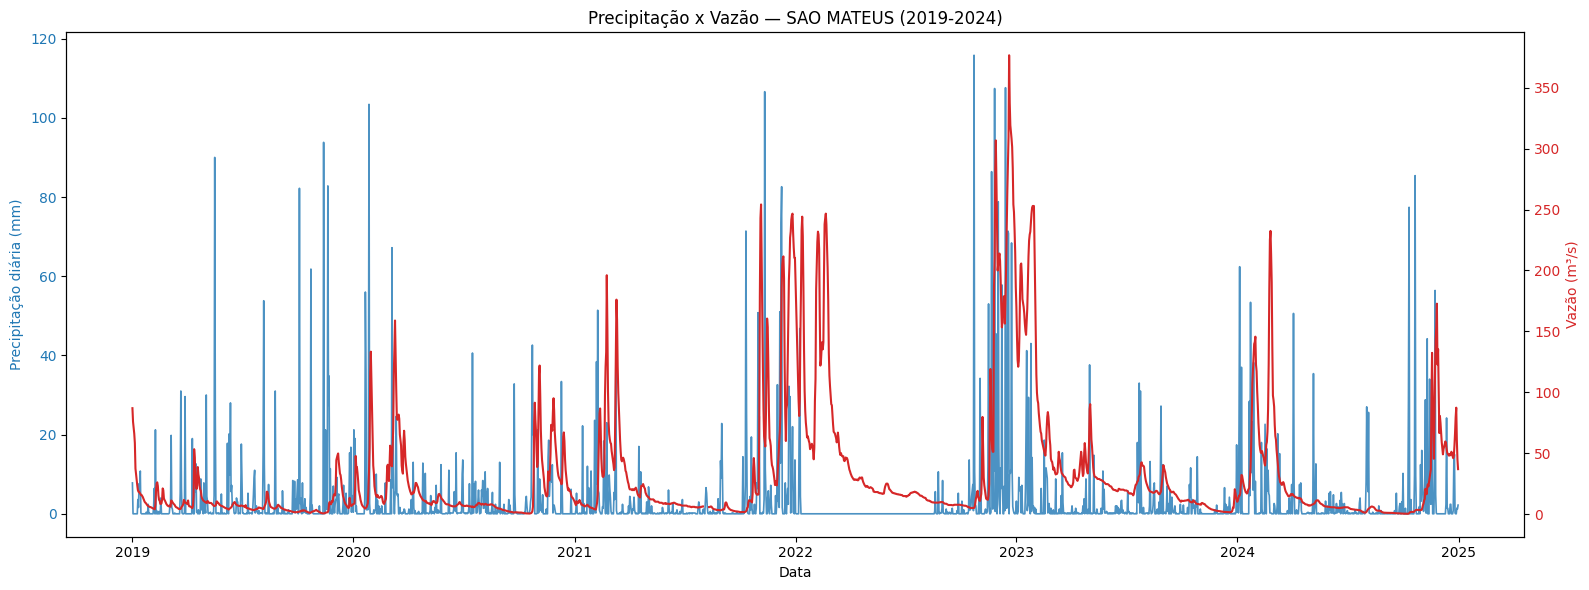

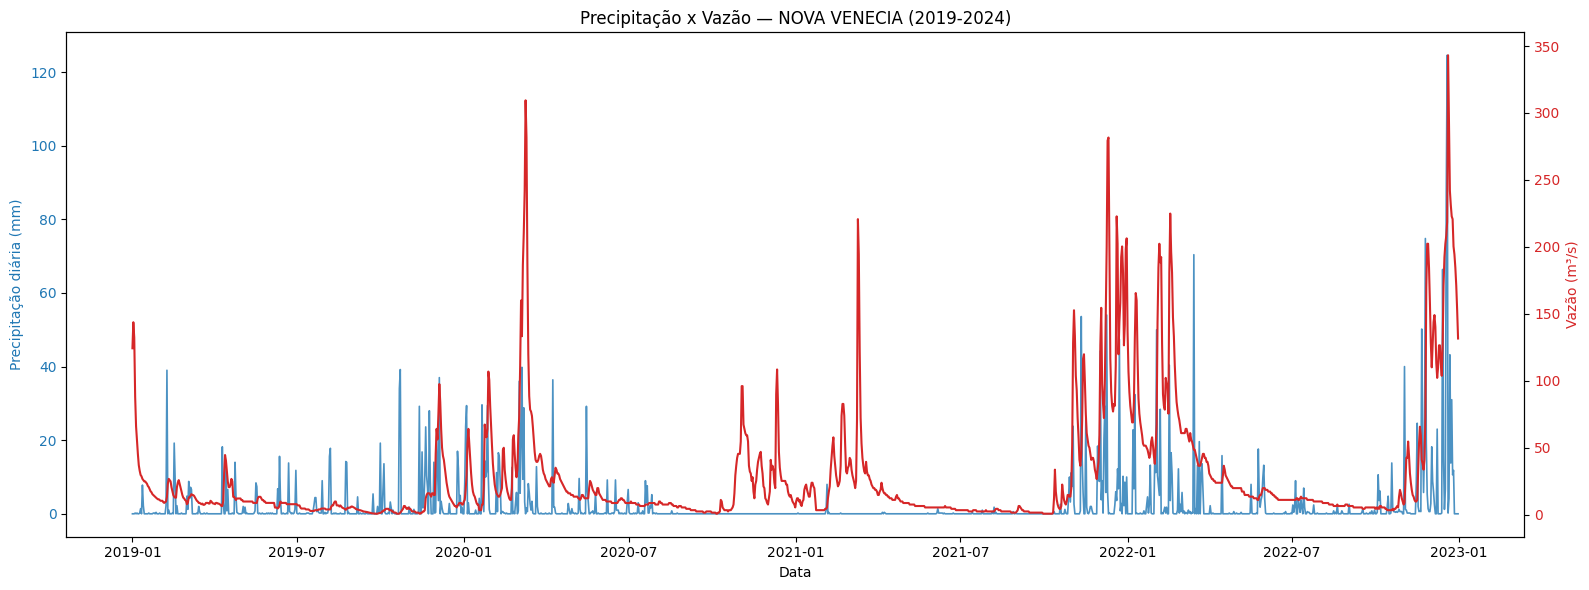

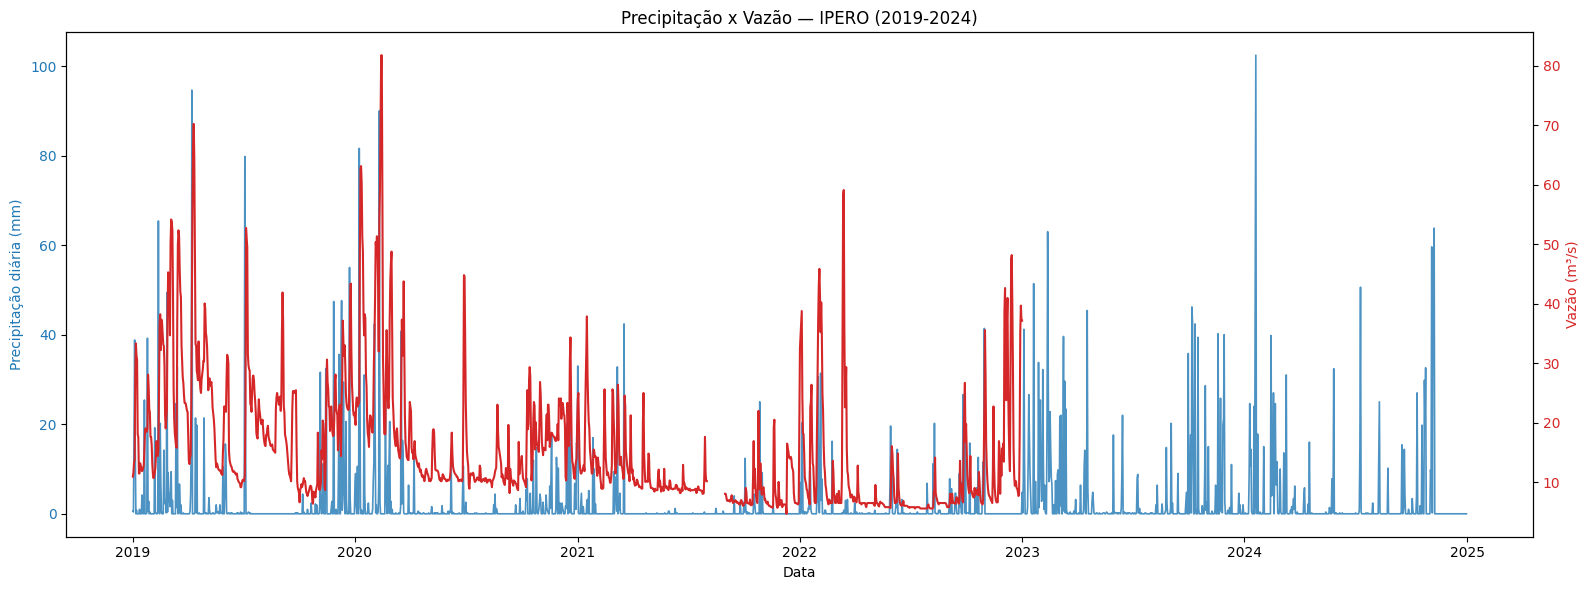

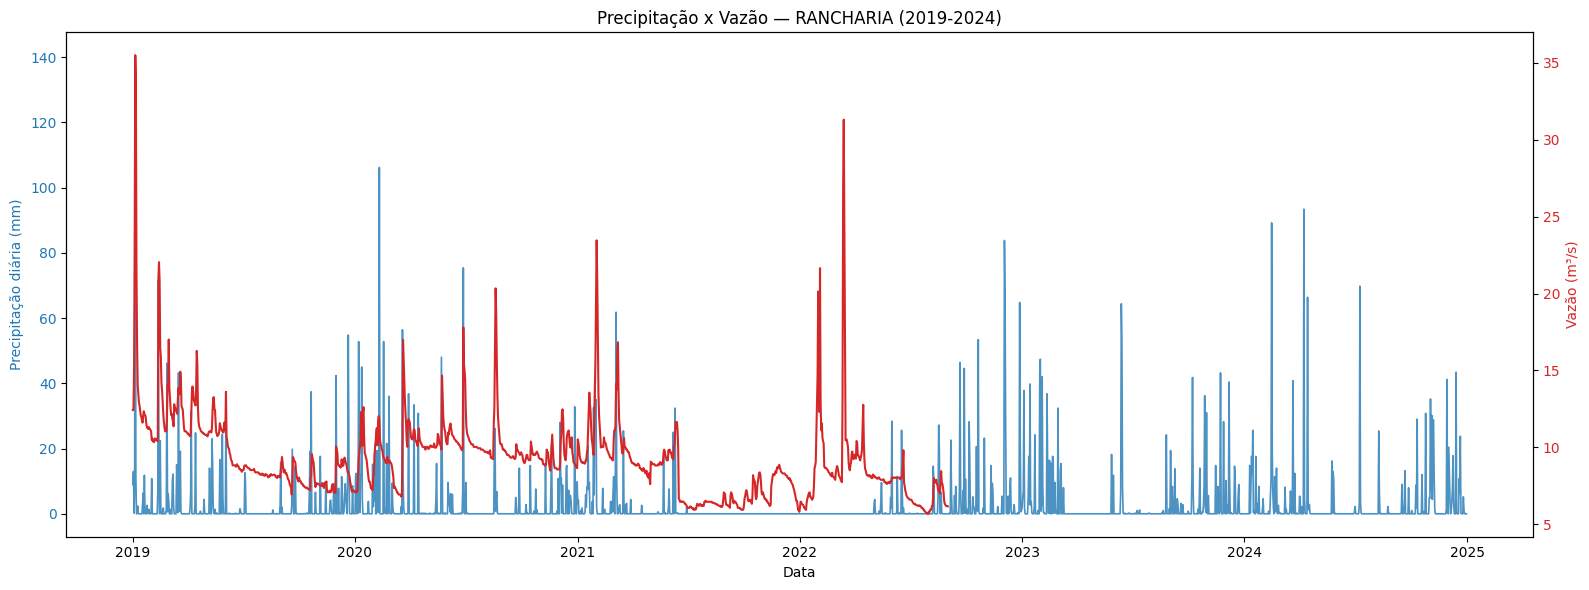

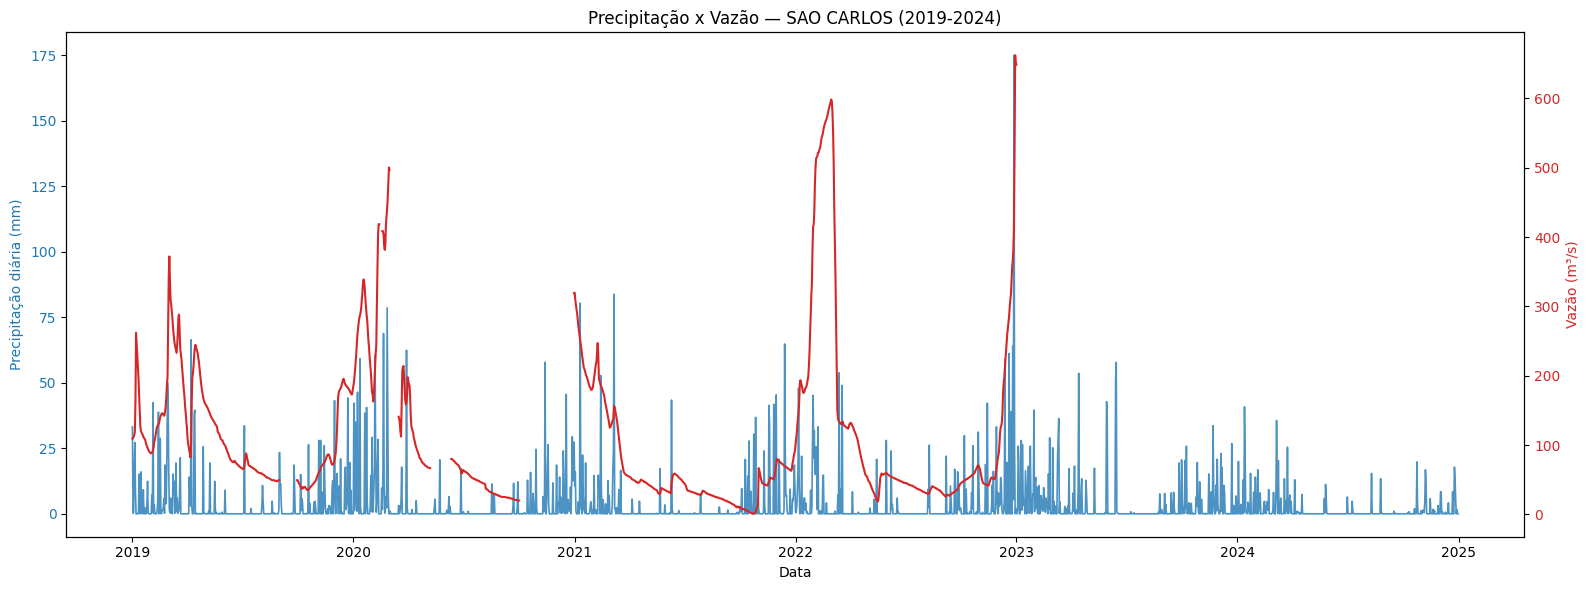


Arquivos criados:
- serie_temporal_SAO_MATEUS.png
- serie_temporal_NOVA_VENECIA.png
- serie_temporal_IPERO.png
- serie_temporal_RANCHARIA.png
- serie_temporal_SAO_CARLOS.png


In [ ]:
def normalizar_municipio(nome: str) -> str:
    if pd.isna(nome):
        return nome
    nome = str(nome).strip().upper()
    nome = unicodedata.normalize("NFKD", nome)
    nome = nome.encode("ascii", "ignore").decode("ascii")
    nome = re.sub(r"\s+", " ", nome)
    return nome

COL_PRECIPITACAO = "PRECIPITAÇÃO TOTAL, HORÁRIO (mm)"
COL_VAZAO = "vazao_m3s"
df_com_ana = df[df["tem_estacao_ana"] == True]
vazao_por_municipio = df_com_ana.groupby("municipio_norm")[COL_VAZAO].count()
municipios_com_vazao = vazao_por_municipio[vazao_por_municipio > 0].index.tolist()

if len(municipios_com_vazao) == 0:
    raise ValueError("Nenhum município com estação ANA possui dados de vazão preenchidos.")

municipios_sorteados = random.sample(municipios_com_vazao, 5)

print("Municípios analisados:")
for m in municipios_sorteados:
    print(f"- {m}")

arquivos_criados = []

for municipio_alvo in municipios_sorteados:
    df_mun = df[df["municipio_norm"] == municipio_alvo].copy()
    df_mun["data"] = pd.to_datetime(df_mun["data"], errors="coerce")
    df_mun["timestamp"] = df_mun["data"] + pd.to_timedelta(df_mun["hora"], unit="h")
    df_mun = df_mun.sort_values("timestamp")

    serie_diaria = (
        df_mun.groupby(df_mun["timestamp"].dt.date)
        .agg(
            precipitacao_mm_dia=(COL_PRECIPITACAO, "sum"),
            vazao_m3s=(COL_VAZAO, "mean"),
        )
        .reset_index()
        .rename(columns={"timestamp": "data"})
    )
    serie_diaria["data"] = pd.to_datetime(serie_diaria["data"])

    fig, ax1 = plt.subplots(figsize=(16, 6))
    cor_precip = "tab:blue"
    ax1.set_xlabel("Data")
    ax1.set_ylabel("Precipitação diária (mm)", color=cor_precip)
    ax1.plot(
        serie_diaria["data"],
        serie_diaria["precipitacao_mm_dia"],
        color=cor_precip,
        linewidth=1.2,
        alpha=0.8,
        label="Precipitação (mm/dia)",
    )
    ax1.tick_params(axis="y", labelcolor=cor_precip)

    ax2 = ax1.twinx()
    cor_vazao = "tab:red"
    ax2.set_ylabel("Vazão (m³/s)", color=cor_vazao)
    ax2.plot(
        serie_diaria["data"],
        serie_diaria["vazao_m3s"],
        color=cor_vazao,
        linewidth=1.5,
        label="Vazão (m³/s)",
    )
    ax2.tick_params(axis="y", labelcolor=cor_vazao)

    plt.title(f"Precipitação x Vazão — {municipio_alvo} (2019-2024)")
    fig.tight_layout()

    nome_grafico = f"serie_temporal_{municipio_alvo.replace(' ', '_')}.png"
    plt.savefig(nome_grafico, dpi=150)
    plt.show()

    arquivos_criados.append(nome_grafico)

print("\nArquivos criados:")
for arquivo in arquivos_criados:
    print(f"- {arquivo}")

Criação da Matriz de Correlação:


Variáveis usadas na matriz de correlação (20):
  - PRECIPITAÇÃO TOTAL, HORÁRIO (mm)
  - PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)
  - PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB)
  - PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB)
  - RADIACAO GLOBAL (KJ/m²)
  - TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)
  - TEMPERATURA DO PONTO DE ORVALHO (°C)
  - TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C)
  - TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C)
  - TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C)
  - TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT) (°C)
  - UMIDADE REL. MAX. NA HORA ANT. (AUT) (%)
  - UMIDADE REL. MIN. NA HORA ANT. (AUT) (%)
  - UMIDADE RELATIVA DO AR, HORARIA (%)
  - VENTO, DIREÇÃO HORARIA (gr) (° (gr))
  - VENTO, RAJADA MAXIMA (m/s)
  - VENTO, VELOCIDADE HORARIA (m/s)
  - chuva_cemaden_mm
  - cota_cm
  - vazao_m3s

Salvo: matriz_correlacao.csv


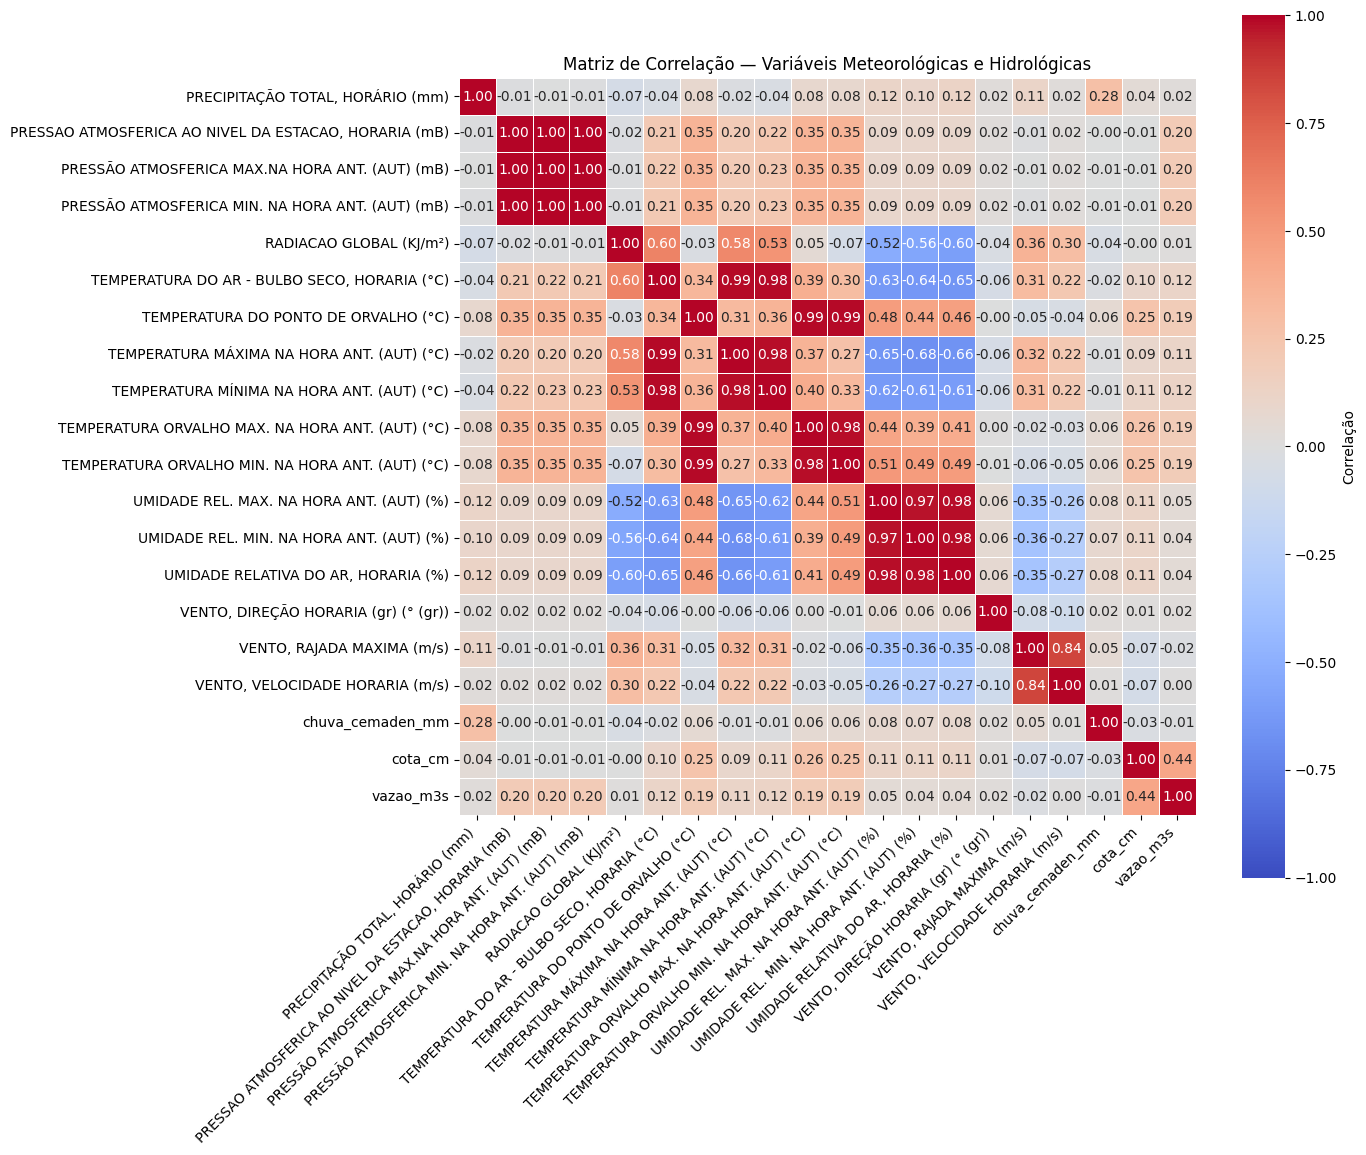


Top 15 pares de maior correlação (em módulo):
                                           variavel_1                                       variavel_2  correlacao
PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB) PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB)    0.999963
      PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB) PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB)    0.999961
PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)  PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB)    0.999958
                 TEMPERATURA DO PONTO DE ORVALHO (°C) TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT) (°C)    0.987811
                 TEMPERATURA DO PONTO DE ORVALHO (°C) TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C)    0.987745
         TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)       TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C)    0.987653
         TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)       TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C)    0.984760
           TEMPERATURA MÁXIMA NA 

In [ ]:
COLUNAS_EXCLUIR = ["hora", "data", "tem_estacao_cemaden", "tem_estacao_ana"]
colunas_numericas = [
    col for col in df.columns
    if pd.api.types.is_numeric_dtype(df[col]) and col not in COLUNAS_EXCLUIR
]
print(f"\nVariáveis usadas na matriz de correlação ({len(colunas_numericas)}):")
for c in colunas_numericas:
    print(f"  - {c}")
matriz_corr = df[colunas_numericas].corr()
matriz_corr.round(3).to_csv("matriz_correlacao.csv", encoding="utf-8")
print("\nSalvo: matriz_correlacao.csv")
plt.figure(figsize=(14, 12))
sns.heatmap(
    matriz_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Correlação"},
)
plt.title("Matriz de Correlação — Variáveis Meteorológicas e Hidrológicas")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("matriz_correlacao.png", dpi=150)
plt.show()
corr_pares = (
    matriz_corr.where(~np.eye(len(matriz_corr), dtype=bool))
    .stack()
    .reset_index()
)
corr_pares.columns = ["variavel_1", "variavel_2", "correlacao"]
corr_pares["par_ordenado"] = corr_pares.apply(
    lambda r: tuple(sorted([r["variavel_1"], r["variavel_2"]])), axis=1
)
corr_pares = corr_pares.drop_duplicates(subset="par_ordenado").drop(columns="par_ordenado")
corr_pares["correlacao_abs"] = corr_pares["correlacao"].abs()
top_correlacoes = corr_pares.sort_values("correlacao_abs", ascending=False).head(15)
print("\nTop 15 pares de maior correlação (em módulo):")
print(top_correlacoes[["variavel_1", "variavel_2", "correlacao"]].to_string(index=False))
top_correlacoes.drop(columns="correlacao_abs").to_csv(
    "top_correlacoes.csv", index=False, encoding="utf-8"
)
print("\nSalvo: top_correlacoes.csv")

**Figura 10 e Tabela 7** — Os dezoito pares de maior correlação absoluta e os blocos de variáveis redundantes.
Em vermelho os pares com |r| ≥ 0,95 (redundância); em azul os que carregam informação genuinamente distinta.

In [ ]:
corr = df[num].corr()

pares = corr.where(~np.eye(len(corr), dtype=bool)).stack().reset_index()
pares.columns = ["v1", "v2", "r"]
pares["chave"] = pares.apply(lambda x: tuple(sorted([x.v1, x.v2])), axis=1)
pares = pares.drop_duplicates("chave").drop(columns="chave")
top = pares.reindex(pares.r.abs().sort_values(ascending=False).index).head(18)

fig, ax = plt.subplots(figsize=(11, 7.5))
lab = [f"{curto(a)}  ×  {curto(b)}" for a, b in zip(top.v1, top.v2)]
cores_barra = [VERMELHO if abs(r) >= 0.95 else (LARANJA if abs(r) >= 0.8 else AZUL) for r in top.r]
ax.barh(range(len(top))[::-1], top.r.values, color=cores_barra, edgecolor="white")
ax.set_yticks(range(len(top))[::-1])
ax.set_yticklabels(lab, fontsize=8.5)
for i, r in zip(range(len(top))[::-1], top.r.values):
    ax.text(r + (0.02 if r > 0 else -0.02), i, f"{r:+.3f}", va="center",
            ha="left" if r > 0 else "right", fontsize=8.5, fontweight="bold")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlim(-1.15, 1.15)
ax.set_xlabel("Correlação de Pearson")
ax.set_title("Seção 3.4 — 18 pares de maior correlação absoluta\n"
             "(vermelho: |r| ≥ 0,95 = redundância; laranja: 0,80–0,95; azul: < 0,80)")
fig.tight_layout()
fig.savefig("3_4_top_correlacoes.png")
plt.show()

sem_diagonal = ~np.eye(len(corr), dtype=bool)
print(f"pares com |r| >= 0,95: {int(((corr.abs() >= 0.95) & sem_diagonal).values.sum() / 2)}")
print(f"pares com |r| >= 0,99: {int(((corr.abs() >= 0.99) & sem_diagonal).values.sum() / 2)}\n")

blocos = {
    "pressão": [c for c in num if "PRESS" in c],
    "temperatura_ar": [c for c in num if "TEMPERATURA" in c and "ORVALHO" not in c],
    "ponto_orvalho": [c for c in num if "ORVALHO" in c],
    "umidade": [c for c in num if "UMIDADE" in c],
}
linhas = []
for grupo, cols in blocos.items():
    sub = corr.loc[cols, cols].where(~np.eye(len(cols), dtype=bool)).stack()
    linhas.append({"bloco": grupo, "n_colunas": len(cols),
                   "r_min": round(sub.min(), 3), "r_max": round(sub.max(), 3)})

tabela_blocos_redundantes = pd.DataFrame(linhas).set_index("bloco")
print("Tabela 7 — Blocos de variáveis redundantes identificados pela matriz de correlação:")
print(tabela_blocos_redundantes.to_string())
tabela_blocos_redundantes.to_csv("tabela_7_blocos_redundantes.csv", encoding="utf-8")

**Figura 11** — Quatro pares de variáveis em dispersão: (a) temperatura × umidade em densidade hexagonal;
(b) concordância entre as duas fontes de chuva; (c) chuva e vazão na mesma hora; (d) cota × vazão, onde o
agrupamento de municípios distintos mascara a relação (efeito de *pooling*).

In [ ]:
amo = df.sample(min(120_000, len(df)), random_state=42)

fig, axes = plt.subplots(2, 2, figsize=(14.5, 11))

a = amo[[T, U]].dropna()
ax = axes[0, 0]
hb = ax.hexbin(a[T], a[U], gridsize=60, cmap="YlOrRd", bins="log", mincnt=1)
plt.colorbar(hb, ax=ax, label="nº de horas (log)")
ax.set_xlabel(curto(T))
ax.set_ylabel(curto(U))
ax.set_title(f"(a) Temperatura × Umidade relativa\n"
             f"Pearson r = {a[T].corr(a[U]):+.3f}  |  Spearman ρ = {a[T].corr(a[U], method='spearman'):+.3f}")

a = amo[[P, C]].dropna()
a = a[(a[P] > 0) | (a[C] > 0)]
ax = axes[0, 1]
ax.scatter(a[P], a[C], alpha=0.12, s=7, color=VERDE, edgecolor="none")
lim = max(a[P].max(), a[C].max())
ax.plot([0, lim], [0, lim], ls="--", color=VERMELHO, lw=1.4, label="identidade (y = x)")
ax.set_xlabel(curto(P))
ax.set_ylabel(curto(C))
ax.set_title(f"(b) Chuva INMET × Chuva CEMADEN (horas com chuva > 0 em alguma fonte)\n"
             f"Pearson r = {a[P].corr(a[C]):+.3f}")
ax.legend(fontsize=8.5)

a = amo[[C, V]].dropna()
ax = axes[1, 0]
ax.scatter(a[C], a[V], alpha=0.18, s=8, color=AZUL, edgecolor="none")
ax.set_xlabel(curto(C))
ax.set_ylabel(curto(V))
ax.set_yscale("symlog")
ax.set_title(f"(c) Chuva CEMADEN × Vazão — MESMA hora\n"
             f"Pearson r = {a[C].corr(a[V]):+.3f}  |  Spearman ρ = {a[C].corr(a[V], method='spearman'):+.3f}  → quase nula")

a = amo[[CO, V, "municipio_norm"]].dropna()
ax = axes[1, 1]
muns = a["municipio_norm"].value_counts().head(6).index
paleta = sns.color_palette("tab10", len(muns))
ax.scatter(a[CO], a[V], alpha=0.10, s=7, color=CINZA, edgecolor="none", label="todos os municípios")
for cor, m in zip(paleta, muns):
    s = a[a["municipio_norm"] == m]
    ax.scatter(s[CO], s[V], alpha=0.65, s=9, color=cor, edgecolor="none", label=m.title())
ax.set_xlabel(curto(CO))
ax.set_ylabel(curto(V))
ax.set_yscale("symlog")
ax.set_title(f"(d) Cota × Vazão — global r = {a[CO].corr(a[V]):+.3f},\nmas cada município é uma curva-chave própria")
ax.legend(fontsize=7.5, markerscale=2, loc="upper left")

fig.suptitle("Seção 3.4 — Gráficos de dispersão entre pares de variáveis", fontsize=14, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.965])
fig.savefig("3_4_dispersao.png")
plt.show()

**Figura 12 e Tabela 8** — Por que a correlação horária chuva × vazão é quase nula: a vazão responde à chuva
com atraso, e o sinal fica mais forte quanto maior a janela de chuva acumulada.

Esta célula constrói a série diária por município (`diario`), reaproveitada mais adiante na Tabela 9.

In [ ]:
d = df[df["tem_estacao_ana"] == True][["municipio_norm", "data", P, C, V]].copy()
diario = (
    d.groupby(["municipio_norm", "data"], observed=True)
     .agg(chuva_inmet=(P, "sum"), chuva_cem=(C, "sum"), vazao=(V, "mean"))
     .reset_index()
     .sort_values(["municipio_norm", "data"])
)
print(f"dias-município: {len(diario):,}")

res = []
for lag in range(0, 11):
    cl = diario.groupby("municipio_norm", observed=True)["chuva_inmet"].shift(lag)
    tmp = pd.DataFrame({"c": cl, "v": diario["vazao"], "m": diario["municipio_norm"]}).dropna()
    r_int = tmp.groupby("m", observed=True)[["c", "v"]].apply(
        lambda x: x["c"].corr(x["v"], method="spearman") if len(x) > 200 else np.nan).dropna()
    res.append({"lag_dias": lag,
                "spearman_mediano_intra_municipio": r_int.median(),
                "spearman_global": tmp["c"].corr(tmp["v"], method="spearman"),
                "n_mun": len(r_int)})
lagdf = pd.DataFrame(res)

res2 = []
for jan in [1, 2, 3, 5, 7, 10, 15, 30, 60]:
    acum = diario.groupby("municipio_norm", observed=True)["chuva_inmet"].transform(
        lambda s: s.rolling(jan, min_periods=max(1, jan // 2)).sum())
    tmp = pd.DataFrame({"c": acum, "v": diario["vazao"], "m": diario["municipio_norm"]}).dropna()
    r_int = tmp.groupby("m", observed=True)[["c", "v"]].apply(
        lambda x: x["c"].corr(x["v"], method="spearman") if len(x) > 200 else np.nan).dropna()
    res2.append({"janela_dias": jan, "spearman_mediano": r_int.median(),
                 "q25": r_int.quantile(0.25), "q75": r_int.quantile(0.75), "n_mun": len(r_int)})
jandf = pd.DataFrame(res2)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))

ax = axes[0]
ax.plot(lagdf.lag_dias, lagdf.spearman_mediano_intra_municipio, "o-", color=AZUL, lw=2, ms=7,
        label="mediana intra-município")
ax.plot(lagdf.lag_dias, lagdf.spearman_global, "s--", color=CINZA, lw=1.6, ms=5,
        label="global (todos juntos)")
imax = lagdf.spearman_mediano_intra_municipio.idxmax()
ax.axvline(lagdf.lag_dias[imax], color=VERMELHO, ls=":", lw=1.6)
ax.annotate(f"pico: {lagdf.lag_dias[imax]:.0f} dias\nρ = {lagdf.spearman_mediano_intra_municipio[imax]:.3f}",
            xy=(lagdf.lag_dias[imax], lagdf.spearman_mediano_intra_municipio[imax]),
            xytext=(5.0, 0.235), fontsize=9, color=VERMELHO, fontweight="bold",
            arrowprops=dict(arrowstyle="->", color=VERMELHO))
ax.set_xlabel("Defasagem aplicada à chuva (dias)")
ax.set_ylabel("Spearman ρ  chuva × vazão")
ax.set_title("(a) A vazão responde à chuva com atraso")
ax.legend(fontsize=9)
ax.set_ylim(0, 0.42)

ax = axes[1]
ax.plot(jandf.janela_dias, jandf.spearman_mediano, "o-", color=VERDE, lw=2.2, ms=7,
        label="mediana entre municípios")
ax.fill_between(jandf.janela_dias, jandf.q25, jandf.q75, color=VERDE, alpha=0.18,
                label="intervalo interquartil")
ax.set_xscale("log")
ax.set_xticks(jandf.janela_dias)
ax.set_xticklabels(jandf.janela_dias)
ax.set_xlabel("Janela de chuva acumulada (dias, escala log)")
ax.set_ylabel("Spearman ρ  chuva acumulada × vazão")
ax.set_title("(b) Quanto maior o acúmulo, mais forte o sinal")
ax.legend(fontsize=9)
for x, y in zip(jandf.janela_dias, jandf.spearman_mediano):
    ax.annotate(f"{y:.2f}", (x, y), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8)

fig.suptitle("Seção 3.4 — Por que a correlação horária chuva × vazão é quase nula: defasagem e acumulação",
             fontsize=13, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig("3_4_defasagem.png")
plt.show()

print("\nTabela 8 — Correlação entre chuva acumulada e vazão do dia:")
print(jandf.round(3).to_string(index=False))
lagdf.to_csv("defasagem_chuva_vazao.csv", index=False, encoding="utf-8")
jandf.to_csv("tabela_8_janela_chuva_vazao.csv", index=False, encoding="utf-8")

**Figura 13** — Achado de integração: `chuva_cemaden_mm` é a **soma** entre as estações do município, não a
média. A chuva registrada cresce com o número de estações, enquanto o INMET (uma estação por município)
permanece estável.

In [ ]:
import glob

def norm_mun(s):
    s = str(s).strip().upper()
    s = unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", s)

est = {}
for f in sorted(glob.glob(str(Path(PASTA_PROJETO) / "CEMADEN_consolidado" / "*.csv"))):
    d_est = pd.read_csv(f, usecols=["municipio", "codEstacao"])
    for m, n in d_est.groupby("municipio")["codEstacao"].nunique().items():
        k = norm_mun(m)
        est[k] = max(est.get(k, 0), int(n))
est = pd.Series(est, name="n_estacoes")
print(f"{len(est)} municípios com estação CEMADEN")

perf = df.groupby("municipio_norm", observed=True).agg(
    chuva_cem_media=(C, "mean"), chuva_cem_max=(C, "max"),
    chuva_inmet_media=(P, "mean"), n=(C, "count")).query("n > 1000")
comp = perf.join(est, how="inner").dropna()
r_p = comp.n_estacoes.corr(comp.chuva_cem_media)
r_s = comp.n_estacoes.corr(comp.chuva_cem_media, method="spearman")
print(f"n={len(comp)} municípios | Pearson={r_p:+.3f} Spearman={r_s:+.3f}")
comp.to_csv("cemaden_estacoes_vs_chuva.csv", encoding="utf-8")

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.8))

ax = axes[0]
ax.scatter(comp.n_estacoes, comp.chuva_cem_media, s=48, color=VERMELHO, alpha=0.75,
           edgecolor="white", linewidth=0.6, label="CEMADEN (agregado por soma)")
ax.scatter(comp.n_estacoes, comp.chuva_inmet_media, s=34, color=AZUL, alpha=0.7,
           edgecolor="white", linewidth=0.5, marker="s", label="INMET (referência, 1 estação)")
z = np.polyfit(comp.n_estacoes, comp.chuva_cem_media, 1)
xs = np.linspace(1, comp.n_estacoes.max(), 50)
ax.plot(xs, np.polyval(z, xs), "--", color=VERMELHO, lw=1.6,
        label=f"ajuste linear: y = {z[0]:.3f}·x + {z[1]:.2f}")
for m in ["SAO PAULO", "RIO DE JANEIRO", "ANGRA DOS REIS", "JUIZ DE FORA"]:
    if m in comp.index:
        ax.annotate(m.title(), (comp.loc[m, "n_estacoes"], comp.loc[m, "chuva_cem_media"]),
                    textcoords="offset points", xytext=(-8, 8), fontsize=8.5, fontweight="bold")
ax.set_xlabel("Nº de estações CEMADEN no município")
ax.set_ylabel("Chuva horária média registrada (mm/h)")
ax.set_title(f"(a) A chuva CEMADEN cresce com o nº de estações\n"
             f"Pearson r = {r_p:+.3f}   (a chuva física não deveria depender disso)")
ax.legend(fontsize=8.5)

ax = axes[1]
faixas = pd.cut(comp.n_estacoes, [0, 1, 2, 5, 10, 200], labels=["1", "2", "3–5", "6–10", ">10"])
g = comp.groupby(faixas, observed=True).agg(
    cem=("chuva_cem_media", "mean"), inm=("chuva_inmet_media", "mean"), n=("n_estacoes", "size"))
x = np.arange(len(g))
w = 0.38
ax.bar(x - w / 2, g.cem, w, color=VERMELHO, label="CEMADEN", edgecolor="white")
ax.bar(x + w / 2, g.inm, w, color=AZUL, label="INMET", edgecolor="white")
for i, (a_, b_, nn) in enumerate(zip(g.cem, g.inm, g.n)):
    ax.text(i - w / 2, a_ + 0.06, f"{a_:.2f}", ha="center", fontsize=8.5, fontweight="bold")
    ax.text(i + w / 2, b_ + 0.06, f"{b_:.2f}", ha="center", fontsize=8.5)
    ax.text(i, a_ + 0.30, f"n={nn}", ha="center", fontsize=7.5, color=CINZA)
ax.set_xticks(x)
ax.set_xticklabels(g.index)
ax.set_xlabel("Nº de estações CEMADEN no município")
ax.set_ylabel("Chuva horária média (mm/h)")
ax.set_title(f"(b) INMET permanece estável; CEMADEN infla {g.cem.iloc[-1] / g.cem.iloc[0]:.0f}×\n"
             f"do município com 1 estação para os com mais de 10")
ax.set_ylim(0, g.cem.max() * 1.22)
ax.legend(fontsize=9)

fig.suptitle("Seção 3.4 — Achado de integração: chuva_cemaden_mm é SOMA entre estações, não média",
             fontsize=13, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig("3_4_achado_cemaden.png")
plt.show()

Análise dos Dados Categóricos

Tabela de frequência - UF:
    frequencia  percentual_%
UF                          
MG     3524736          47.3
SP     2117472          28.4
RJ     1149864          15.4
ES      666360           8.9


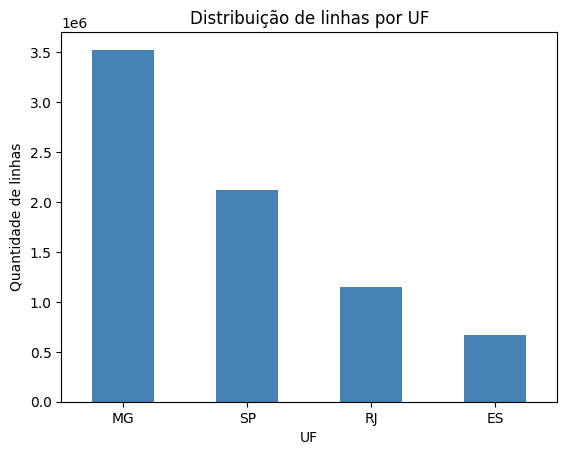


Tabela de frequência - tem_estacao_cemaden (por município):
                     frequencia  percentual_%
tem_estacao_cemaden                          
True                         86          58.9
False                        60          41.1


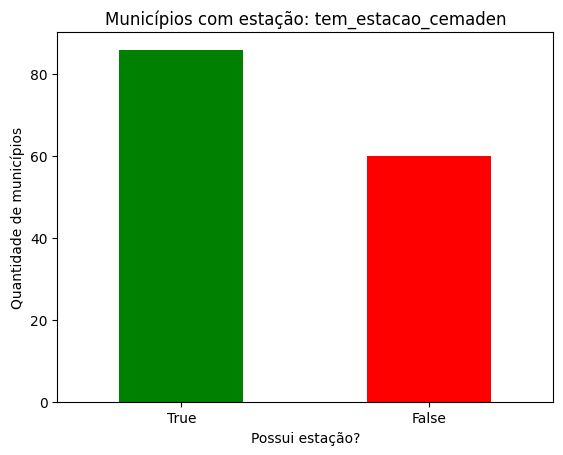


Tabela de frequência - tem_estacao_ana (por município):
                 frequencia  percentual_%
tem_estacao_ana                          
False                    94          64.4
True                     52          35.6


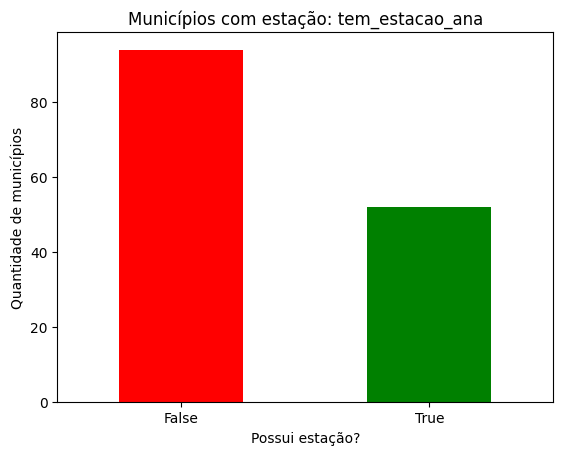


Total de municípios distintos: 146

Municípios com cobertura temporal incompleta:
municipio_norm
JANAUBA            17544
PATY DO ALFERES    18792
ITATIAIA           26304
SAO SEBASTIAO      26304
VOTUPORANGA        26304
POMPEU             35064
SOROCABA           35064
NOVA VENECIA       35064
BEBEDOURO          43848
OURINHOS           43848
SAO SIMAO          48216
Name: count, dtype: int64


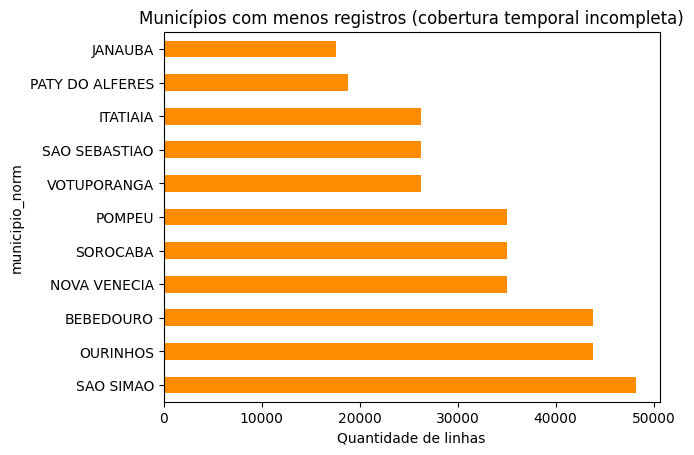

7
count
17544      1
18792      1
26304      3
35064      3
43848      2
48216      1
52608    135
Name: count, dtype: int64


In [ ]:
df = pd.read_csv(PASTA_PROJETO + "dataset_limpo_final.csv")

freq_uf = df['UF'].value_counts()
freq_uf_pct = df['UF'].value_counts(normalize=True) * 100

print("Tabela de frequência - UF:")
print(pd.DataFrame({'frequencia': freq_uf, 'percentual_%': freq_uf_pct.round(1)}))

freq_uf.plot(kind='bar', color='steelblue')
plt.title('Distribuição de linhas por UF')
plt.xlabel('UF')
plt.ylabel('Quantidade de linhas')
plt.xticks(rotation=0)
plt.show()

for col in ['tem_estacao_cemaden', 'tem_estacao_ana']:
    freq = df.drop_duplicates('municipio_norm')[col].value_counts()
    freq_pct = df.drop_duplicates('municipio_norm')[col].value_counts(normalize=True) * 100

    print(f"\nTabela de frequência - {col} (por município):")
    print(pd.DataFrame({'frequencia': freq, 'percentual_%': freq_pct.round(1)}))

    cores = {'True': 'green', 'False': 'red'}
    cores_ordenadas = [cores[str(idx)] for idx in freq.index]
    freq.plot(kind='bar', color=cores_ordenadas)
    plt.title(f'Municípios com estação: {col}')
    plt.xlabel('Possui estação?')
    plt.ylabel('Quantidade de municípios')
    plt.xticks(rotation=0)
    plt.show()

print(f"\nTotal de municípios distintos: {df['municipio_norm'].nunique()}")

bottom_municipios = df['municipio_norm'].value_counts().sort_values().head(11)
print("\nMunicípios com cobertura temporal incompleta:")
print(bottom_municipios)

bottom_municipios.plot(kind='barh', color='darkorange')
plt.title('Municípios com menos registros (cobertura temporal incompleta)')
plt.xlabel('Quantidade de linhas')
plt.gca().invert_yaxis()
plt.show()

print(df['municipio_norm'].value_counts().nunique())
print(df['municipio_norm'].value_counts().value_counts().sort_index())

Série Temporal - Juiz de Fora (2023)


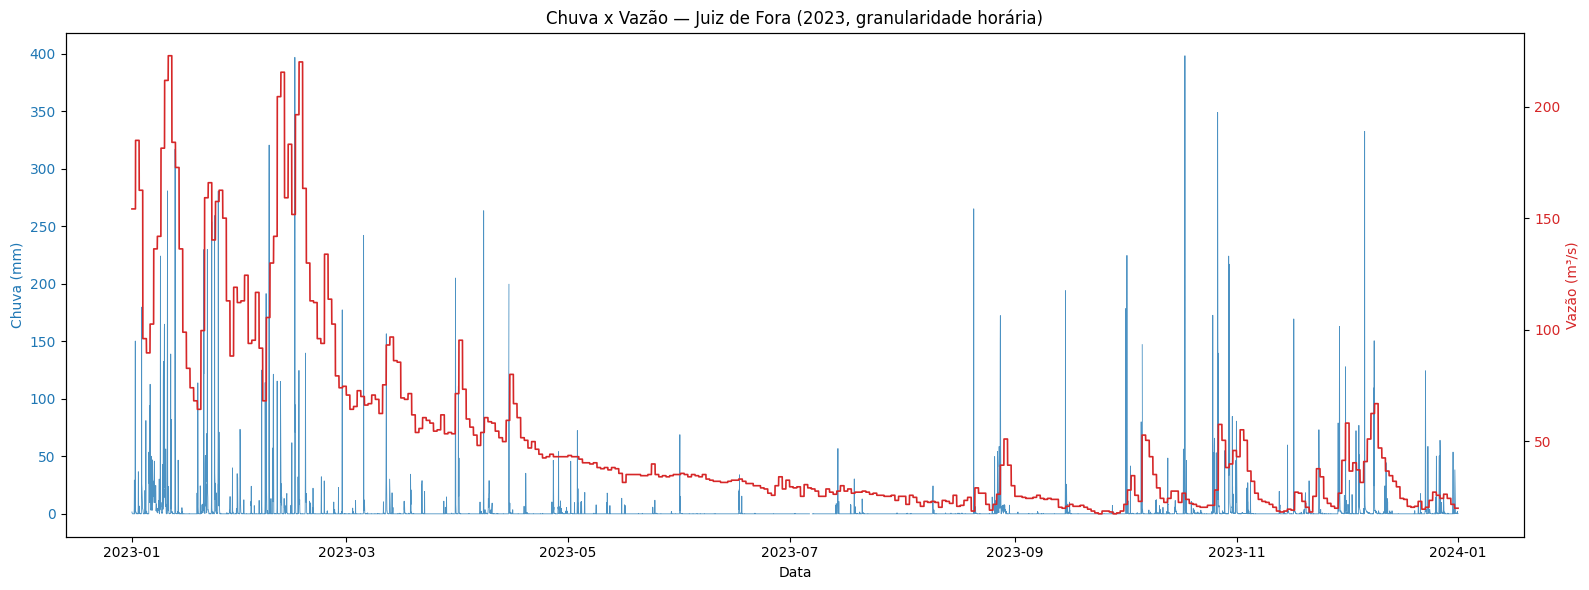

In [ ]:
ANO = 2023

df_jf_recorte = df_jf[df_jf["timestamp"].dt.year == ANO]

fig, ax1 = plt.subplots(figsize=(16, 6))
cor_precip = "tab:blue"
ax1.set_xlabel("Data")
ax1.set_ylabel("Chuva (mm)", color=cor_precip)
ax1.plot(df_jf_recorte["timestamp"], df_jf_recorte["chuva_cemaden_mm"], color=cor_precip, linewidth=0.6, alpha=0.8)
ax1.tick_params(axis="y", labelcolor=cor_precip)

ax2 = ax1.twinx()
cor_vazao = "tab:red"
ax2.set_ylabel("Vazão (m³/s)", color=cor_vazao)
ax2.plot(df_jf_recorte["timestamp"], df_jf_recorte["vazao_m3s"], color=cor_vazao, linewidth=1.2)
ax2.tick_params(axis="y", labelcolor=cor_vazao)

plt.title(f"Chuva x Vazão — Juiz de Fora ({ANO}, granularidade horária)")
fig.tight_layout()
plt.savefig(f"serie_temporal_jf_{ANO}.png", dpi=150)
plt.show()

146 86 52


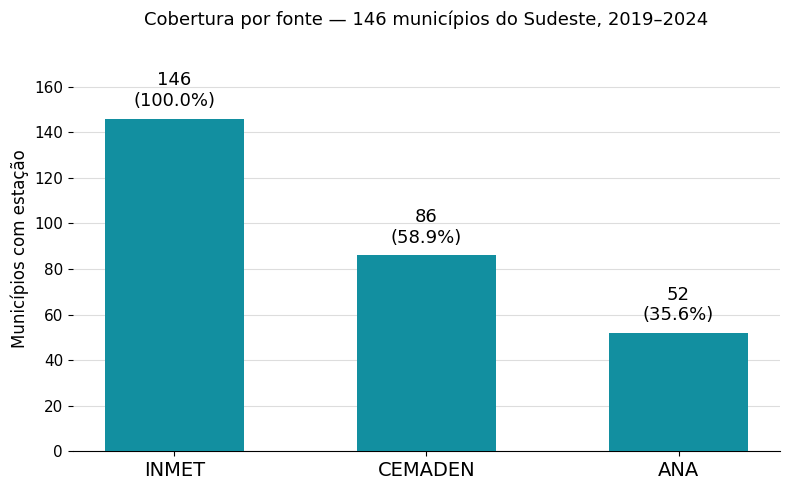

In [ ]:
mun = df.drop_duplicates(subset=['municipio_norm', 'UF']).copy()

for col in ['tem_estacao_cemaden', 'tem_estacao_ana']:
    if mun[col].dtype == object:
        mun[col] = mun[col].astype(str).str.strip().str.lower().isin(['true', '1', 'sim'])

total = len(mun)
n_cemaden = int(mun['tem_estacao_cemaden'].sum())
n_ana = int(mun['tem_estacao_ana'].sum())

print(total, n_cemaden, n_ana)

fontes = ['INMET', 'CEMADEN', 'ANA']
valores = [total, n_cemaden, n_ana]

fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.bar(fontes, valores, color='#128FA0', width=0.55, zorder=3)

for barra, valor in zip(barras, valores):
    ax.text(barra.get_x() + barra.get_width() / 2,
            valor + total * 0.025,
            f'{valor}\n({valor / total * 100:.1f}%)',
            ha='center', va='bottom', fontsize=13)

ax.set_ylabel('Municípios com estação', fontsize=12)
ax.set_ylim(0, total * 1.22)
ax.set_title(f'Cobertura por fonte — {total} municípios do Sudeste, 2019–2024',
             fontsize=13, pad=15)
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=11)
ax.grid(axis='y', color='#DDDDDD', linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

fig.tight_layout()
fig.savefig('cobertura_fontes.png', dpi=300, facecolor='white')
fig.savefig('cobertura_fontes.svg', facecolor='white')
plt.show()

### Análise Geoespacial

**Figura 16** — Precipitação média anual e vazão média por município. Os municípios são geocodificados por
cruzamento com a tabela pública de coordenadas do IBGE.

In [ ]:
ibge = pd.read_csv("https://raw.githubusercontent.com/kelvins/municipios-brasileiros/main/csv/municipios.csv")
ibge["municipio_norm"] = ibge["nome"].map(norm_mun)
UF_COD = {"ES": 32, "MG": 31, "RJ": 33, "SP": 35}
sud = ibge[ibge.codigo_uf.isin(UF_COD.values())]

med = df.groupby(["municipio_norm", "UF"], observed=True).agg(
    precip_media=(P, "mean"), vazao_media=(V, "mean"), cota_media=(CO, "mean"), n=(P, "size")).reset_index()
med["cod"] = med.UF.map(UF_COD)
geo = med.merge(sud[["municipio_norm", "codigo_uf", "latitude", "longitude"]],
                left_on=["municipio_norm", "cod"], right_on=["municipio_norm", "codigo_uf"], how="inner")
geo["precip_anual"] = geo.precip_media * 24 * 365.25
print(f"geocodificados: {len(geo)} de {med.municipio_norm.nunique()} municípios")
geo.to_csv("geo_municipios.csv", index=False, encoding="utf-8")

import matplotlib.colors as mc

fig, axes = plt.subplots(1, 2, figsize=(16.5, 6.8))
for ax, (col, cmap, tit, unid) in zip(axes, [
        ("precip_anual", "YlGnBu", "Precipitação média anual (INMET)", "mm/ano"),
        ("vazao_media", "Reds", "Vazão média (ANA/HidroWeb)", "m³/s")]):
    ax.scatter(sud.longitude, sud.latitude, s=1.2, color="#e8e8e8", zorder=1)
    g = geo.dropna(subset=[col])
    kw = dict(s=95, edgecolor="#333333", linewidth=0.5, zorder=3, cmap=cmap)
    if col == "vazao_media":
        sc = ax.scatter(g.longitude, g.latitude, c=g[col],
                        norm=mc.LogNorm(vmin=max(g[col].min(), 0.5), vmax=g[col].max()), **kw)
    else:
        sc = ax.scatter(g.longitude, g.latitude, c=g[col], **kw)
    plt.colorbar(sc, ax=ax, label=unid + (" (escala log)" if col == "vazao_media" else ""), shrink=0.8)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title(f"{tit}\n{len(g)} municípios com dado")
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
    for _, r in g.nlargest(4, col).iterrows():
        ax.annotate(r.municipio_norm.title(), (r.longitude, r.latitude),
                    textcoords="offset points", xytext=(6, 5), fontsize=8, fontweight="bold")

fig.suptitle("Seção 3.4 — Distribuição espacial no Sudeste (pontos cinza = todos os municípios da região)",
             fontsize=13, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.97])
fig.savefig("3_4_geoespacial.png")
plt.show()

**Figura 17** — Combinação de fontes disponíveis em cada município. A ausência de dados hidrológicos é uma
característica geográfica da rede de monitoramento, não uma falha de medição.

In [ ]:
cob2 = df.groupby(["municipio_norm", "UF"], observed=True).agg(
    cem=("tem_estacao_cemaden", "max"), ana=("tem_estacao_ana", "max")).reset_index()
cob2["cem"] = cob2["cem"].astype(bool)
cob2["ana"] = cob2["ana"].astype(bool)
cob2["cod"] = cob2.UF.map(UF_COD)
cg = cob2.merge(sud[["municipio_norm", "codigo_uf", "latitude", "longitude"]],
                left_on=["municipio_norm", "cod"], right_on=["municipio_norm", "codigo_uf"], how="inner")
cg["cls"] = np.select([cg.cem & cg.ana, cg.cem & ~cg.ana, ~cg.cem & cg.ana],
                      ["INMET + CEMADEN + ANA", "INMET + CEMADEN", "INMET + ANA"], "somente INMET")

fig, ax = plt.subplots(figsize=(9.5, 8.5))
ax.scatter(sud.longitude, sud.latitude, s=1.2, color="#ececec", zorder=1)
for cls, cor, mk in [("INMET + CEMADEN + ANA", VERDE, "o"), ("INMET + CEMADEN", AZUL, "^"),
                     ("INMET + ANA", LARANJA, "s"), ("somente INMET", VERMELHO, "X")]:
    s = cg[cg.cls == cls]
    ax.scatter(s.longitude, s.latitude, s=85, color=cor, marker=mk, edgecolor="#333", linewidth=0.5,
               label=f"{cls} ({len(s)})", zorder=3)
ax.legend(fontsize=9.5, loc="lower left", title="Fontes disponíveis no município")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")
ax.grid(alpha=0.3)
ax.set_title("Seção 3.4 — Cobertura das três fontes por município\n"
             "A ausência de cota/vazão é geográfica, não falha de sensor")
fig.tight_layout()
fig.savefig("3_4_cobertura_fontes_mapa.png")
plt.show()

print(cg.cls.value_counts().to_string())

### Eventos Extremos

**Tabela 9** — Frequência dos eventos extremos sob três definições operacionais. Mostra o desbalanceamento de
classes que a modelagem da Sprint 2 terá de enfrentar.

In [ ]:
dv = diario.dropna(subset=["vazao"])
linhas = []
for q in [0.95, 0.99]:
    lim = dv.groupby("municipio_norm", observed=True)["vazao"].transform(lambda s: s.quantile(q))
    n_ext = int((dv.vazao > lim).sum())
    linhas.append({
        "definição": f"vazão diária acima do p{int(q * 100)} do próprio município",
        "universo": f"{len(dv):,} dias-município com vazão",
        "eventos": n_ext,
        "%": round(100 * n_ext / len(dv), 2),
        "proporção": f"1:{(len(dv) - n_ext) / max(n_ext, 1):.0f}",
    })

n_h = int((df[P] > 25).sum())
tot_h = int(df[P].notna().sum())
linhas.append({
    "definição": "hora com chuva INMET > 25 mm/h",
    "universo": f"{tot_h:,} horas com medição",
    "eventos": n_h,
    "%": round(100 * n_h / tot_h, 4),
    "proporção": f"1:{tot_h / max(n_h, 1):.0f}",
})

tabela_eventos_extremos = pd.DataFrame(linhas)
print("Tabela 9 — Frequência dos eventos extremos sob três definições operacionais:")
print(tabela_eventos_extremos.to_string(index=False))
tabela_eventos_extremos.to_csv("tabela_9_eventos_extremos.csv", index=False, encoding="utf-8")